# Support Vector Machine (SVM)

## Motivation
##### Support Vector Machine (SVM) is a supervised machine learning algorithm designed to find the optimal decision boundary that maximizes the separation between classes. Linear SVM is particularly well suited for high-dimensional datasets with relatively few samples, making it a common choice for genomic and transcriptomic studies. In this analysis, a linear SVM was trained to predict immunotherapy response using molecular and clinical features, while also providing interpretable feature coefficients that indicate each feature's contribution to the classification decision.

In [1]:
## Loading all the required libraries

import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.svm import SVC
import matplotlib.pyplot as plt
from src.utils.plots import plot_cv_metrics, corr_heatmap, missin_val_heatmap, select_threshold_from_cv, plot_external_validation_curves
from src.utils.plots import stacked_bar_chart, plot_hyperparam_search, violin_plot_predictions, forest_plot_coefficients, plot_bootstrap_ci_forest, plot_svm_hyperparam_search
import warnings
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from typing import Literal
from typing import Literal
from scipy import stats
import yaml
import argparse
from src.utils.config import load_config
from src.utils.helper_func import calculate_binary_metrics, stratified_bootstrap_external_metrics, bootstrap_external_metrics, feature_significance
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  roc_auc_score, confusion_matrix, average_precision_score, f1_score, recall_score, precision_score,  ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV


In [2]:
# Loading parameters from configuration file
args = {"config":"configs/Params_set.yml"}

cfg = load_config(args["config"])


## Part A. Training Cohort Overview

In [3]:
# Loading training and validation cohort

training_cohort = pd.read_excel(cfg["Features"]["Final_Checkmate"], sheet_name="Features")
validation_cohort = pd.read_excel(cfg["Features"]["Final_Emtab"], sheet_name="Features")

In [4]:
train_class_labels = training_cohort["Response"].value_counts()
val_class_labels = validation_cohort["Response"].value_counts()
class_labels = pd.concat([train_class_labels, val_class_labels], axis = 1)

### A1. The following plot shows the distribution of class labels in the training and external validation cohorts.

(<Figure size 480x360 with 1 Axes>,
 <Axes: title={'center': 'Number of patients in each class label'}>)

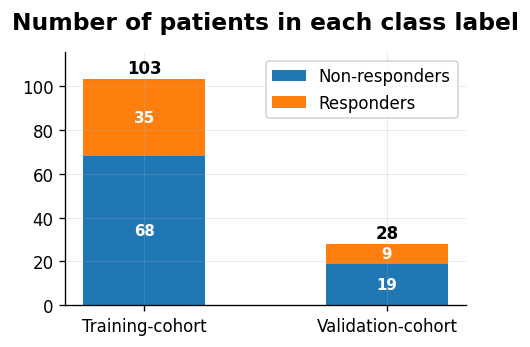

In [5]:
stacked_bar_chart(["Training-cohort", "Validation-cohort"],categories=["Non-responders", "Responders"], 
                  values = [class_labels.iloc[0,:], class_labels.iloc[1,:]], title = "Number of patients in each class label",  figsize = [4,3])

In [6]:
training_cohort.head()

,Received_Prior_Therapy,TMB_Counts,BAP1,PBRM1,SETD2,VHL,Response,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation,Tumor_inflammation_score,Cohort
0,Yes,105.0,WT,MUT,WT,WT,Non-Responders,0.148237,0.207268,0.426179,-0.718344,-0.802468,-0.972039,-1.191040,-0.094806,0.388907,-0.236995,CM-025
1,Yes,28.0,WT,WT,WT,WT,Responders,1.174420,-0.074041,-1.016133,0.081855,-0.003479,1.047075,0.809109,0.484398,-0.572133,1.030557,CM-025
2,Yes,181.0,WT,MUT,WT,WT,Responders,-0.260588,0.973303,1.286888,-0.856730,-0.832729,-0.669412,-1.164171,-1.296157,-0.321287,-0.652298,CM-025
3,Yes,NaN,NaN,NaN,NaN,NaN,Non-Responders,0.035187,-0.310847,0.106104,0.490507,1.029595,1.261651,0.551131,0.209985,-0.929884,0.443611,CM-025
4,Yes,NaN,NaN,NaN,NaN,NaN,Responders,1.560963,-0.515835,-0.646998,0.809698,-0.208788,0.236488,0.165933,1.066020,0.568143,0.553803,CM-025


### A2. Missing Data Distribution Training Cohort

##### The following heatmap illustrates the pattern of missing values across all features in the training cohort. Missing values are primarily observed in the TMB_Counts, BAP1, PBRM1, SETD2, VHL features. The missing values will be imputed using the median strategy within the preprocessing pipeline, with imputation parameters learned from the training data to prevent information leakage. 

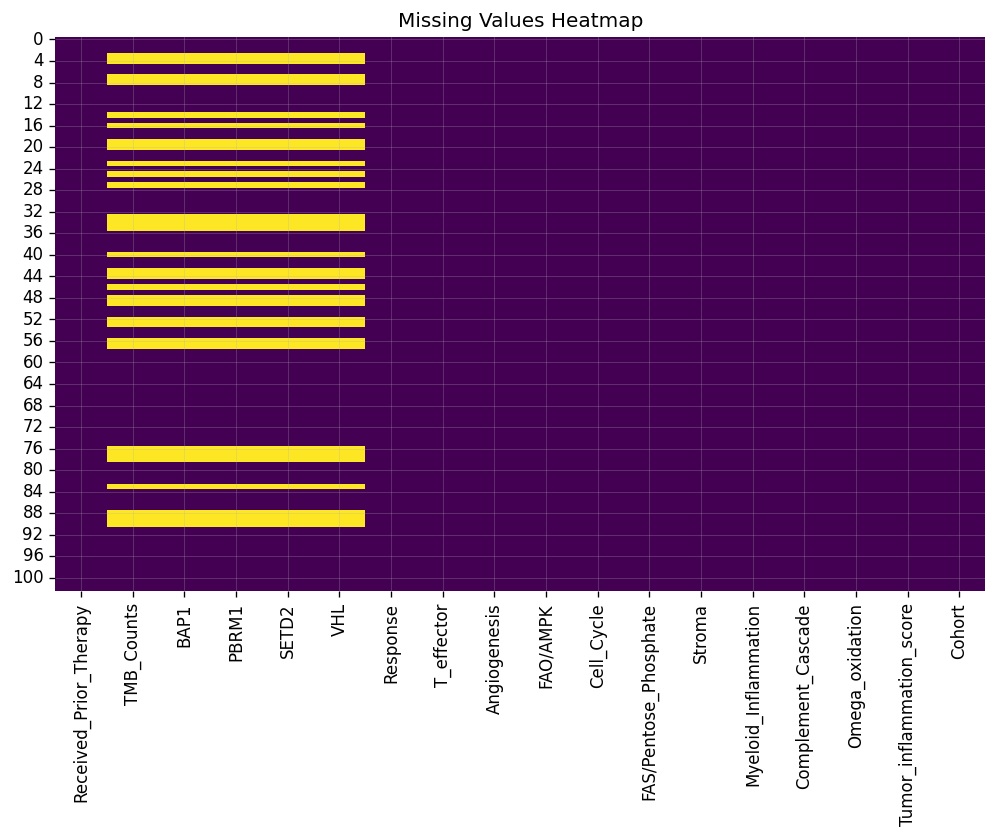

In [7]:
missin_val_heatmap(training_cohort)

## Part B. Feature engineering

### B1. Binary Encoding of Categorical Features

In [8]:

training_cohort["VHL"] = training_cohort["VHL"].map({
    "WT": 0,
    "MUT": 1
})

training_cohort["BAP1"] = training_cohort["BAP1"].map({
    "WT": 0,
    "MUT": 1
})

training_cohort["PBRM1"] = training_cohort["PBRM1"].map({
    "WT": 0,
    "MUT": 1
})

training_cohort["SETD2"] = training_cohort["SETD2"].map({
    "WT": 0,
    "MUT": 1
})

### B2. Since VHL is the originator or founding mutation of ccRCC and observed in 60% to 70% most of patients, hence we wont consider in our feature list. 

In [9]:
training_cohort.drop(columns=[ "VHL", "Received_Prior_Therapy","Cohort"], inplace=True)

In [10]:
corr_mat = training_cohort.drop("Response", axis = 1).corr()

### B3. Pairwise Correlation of Training Cohort Features

##### The following correlation heatmap illustrates the pairwise relationships among the molecular and clinical features in the training cohort. Most feature pairs exhibit weak to moderate correlations, indicating limited multicollinearity. However, the T_effector signature and Tumor Inflammation Score show a strong positive correlation (r = 0.84), suggesting that they capture similar biological information. To reduce multicollinearity and avoid redundancy in the feature set, Tumor Inflammation Score will be excluded from subsequent analyses, while T_effector will be retained due to its well-established association with immunotherapy response.

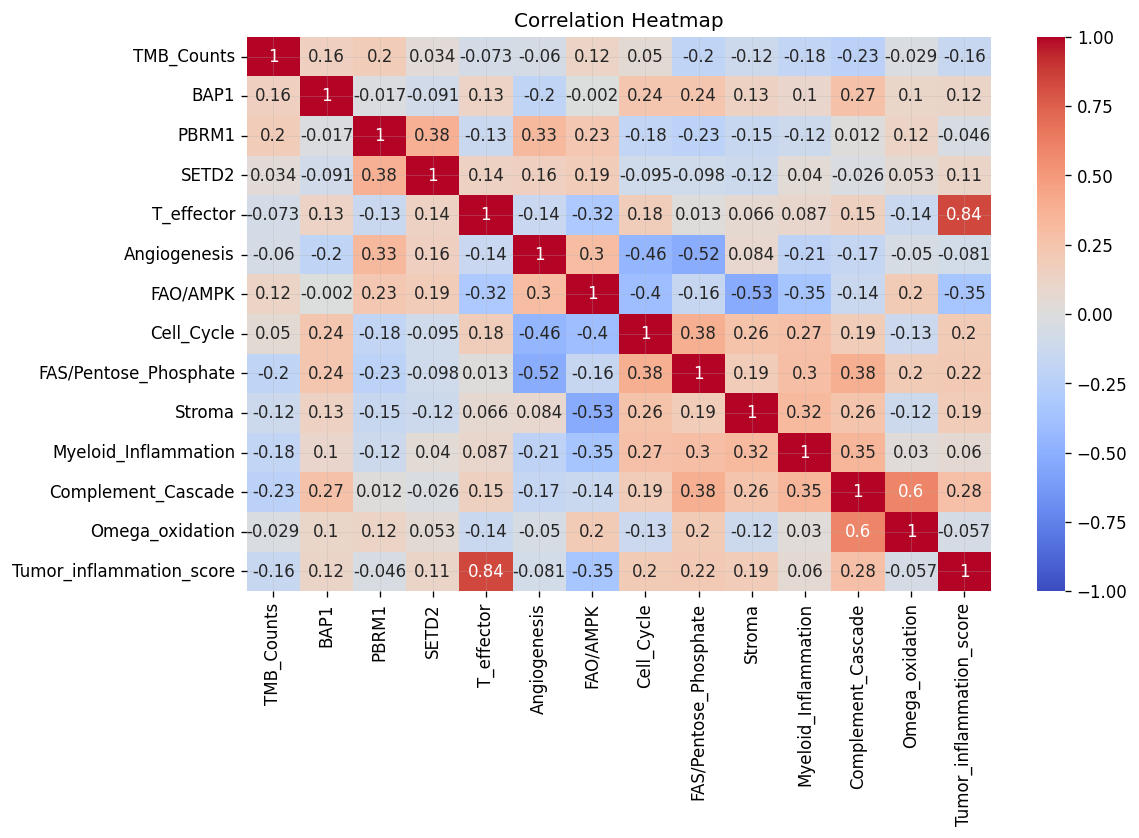

In [11]:
corr_heatmap(corr_mat)

In [12]:
# T_effector and Tumor_inflammation_score are highly correlated. To reduce the multicollinearity, Tumar_inflammation_score is excluded from the feature set.

training_cohort.drop(columns=["Tumor_inflammation_score"], inplace=True)

### B4. Splitting training cohort into training features and the target variable.

In [13]:
X = training_cohort.drop(columns="Response")
y = training_cohort["Response"]

### B5. Encoding target variable into binary variable.

In [14]:
y = y.replace({
    "Non-Responders": 0,
    "Responders": 1
})

In [15]:
y.value_counts()

Response
0    68
1    35
Name: count, dtype: int64

## Part C. Hyperparameter Tuning

##### Hyperparameter tuning was performed to identify the optimal combination of model parameters that maximizes predictive performance. The search was conducted using repeated stratified cross-validation to improve model generalization while reducing the risk of overfitting.


### C1. Modeling Pipeline Creation

In [16]:
# Dividing model features into numeric and binary types.

num_fetres = ["T_effector", "Angiogenesis", "FAO/AMPK", "Cell_Cycle", "TMB_Counts", "FAS/Pentose_Phosphate", "Stroma", "Myeloid_Inflammation",
               "Complement_Cascade", "Omega_oxidation"]
binary_fetres = ["PBRM1","BAP1", "SETD2"]

In [17]:
## Creating pipeline to perform preprocessing of data

binary_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
numeric_pipeline  = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
#cat_pipline = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),("encoder", OneHotEncoder(handle_unknown="ignore", drop = "if_binary"))])
preprocessor = ColumnTransformer([("binary", binary_pipeline, binary_fetres), ("num", numeric_pipeline, num_fetres)]) #, ("cat", cat_pipline, cat_fetres)

pipeline = Pipeline([("preprocessor", preprocessor), ("model", SVC(kernel = "linear"))])



### C2. Hyperparameter Search Space

In [18]:

param_grid = [

{
    "model__kernel":["linear"],
    "model__C":[0.001,0.01,0.1,1,10,100],
    "model__class_weight":[ None,"balanced"]
},

{
    "model__kernel":["rbf"],
    "model__C":[0.01,0.1,1,10,100],
   "model__gamma":["scale","auto",0.001,0.01,0.1,1],
    "model__class_weight":[None, "balanced"]

}

]

### C3. Cross-Validation Strategy

In [19]:

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

### C4. Grid Search

In [20]:

grid = GridSearchCV(estimator =pipeline,
              param_grid=param_grid, 
              cv=cv, 
              scoring= { 'f1': 'f1', "sensitivity":"recall", "auprc":"average_precision", "auroc":"roc_auc"},
              n_jobs=-1,
              refit="auprc")

grid.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...l='linear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'model__C': [0.001, 0.01, ...], 'model__class_weight': [None, 'balanced'], 'model__kernel': ['linear']}, {'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced'], 'model__gamma': ['scale', 'auto', ...], 'model__kernel': ['rbf']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'auprc': 'average_precision', 'auroc': 'roc_auc', 'f1': 'f1', 'sensitivity': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'auprc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... vers

### C5. Best Hyperparameters

In [21]:
grid.best_params_

{'model__C': 1, 'model__class_weight': None, 'model__kernel': 'linear'}

### C6. Best AUPRC score

In [22]:
grid.best_score_

np.float64(0.49804696601987625)

In [23]:
param_res = pd.DataFrame(grid.cv_results_)

In [24]:
param_res.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__C,param_model__class_weight,param_model__kernel,param_model__gamma,params,split0_test_f1,...,split43_test_auroc,split44_test_auroc,split45_test_auroc,split46_test_auroc,split47_test_auroc,split48_test_auroc,split49_test_auroc,mean_test_auroc,std_test_auroc,rank_test_auroc
0,0.025570,0.002353,0.038361,0.002309,0.001,None,linear,NaN,"{'model__C': 0.001, 'model__class_weight': Non...",0.000000,...,0.538462,0.549451,0.744898,0.551020,0.755102,0.461538,0.252747,0.543108,0.134949,33
1,0.022260,0.002430,0.032032,0.002908,0.001,balanced,linear,NaN,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.000000,...,0.516484,0.538462,0.591837,0.663265,0.612245,0.406593,0.186813,0.472732,0.116052,64
2,0.017801,0.002419,0.028794,0.002628,0.010,None,linear,NaN,"{'model__C': 0.01, 'model__class_weight': None...",0.000000,...,0.516484,0.538462,0.714286,0.551020,0.683673,0.450549,0.252747,0.540392,0.130554,38
3,0.019670,0.002262,0.030193,0.002779,0.010,balanced,linear,NaN,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.461538,...,0.516484,0.538462,0.591837,0.663265,0.612245,0.417582,0.186813,0.472527,0.116472,65
4,0.017675,0.001617,0.027814,0.002664,0.100,None,linear,NaN,"{'model__C': 0.1, 'model__class_weight': None,...",0.000000,...,0.527473,0.538462,0.714286,0.551020,0.673469,0.450549,0.241758,0.542920,0.132968,34


### C7. SVM Hyperparameter Search

##### The following figure presents the hyperparameter tuning results for the linear and RBF SVM models using repeated stratified cross-validation. The top row shows the mean AUROC, while the bottom row shows the mean AUPRC across different hyperparameter combinations. Shaded regions represent the variability across cross-validation folds, and the optimal parameter combination for each kernel is indicated by a star. Although the RBF kernel explored a larger hyperparameter space (C, γ, and class weighting), it did not provide a meaningful improvement over the linear kernel. Therefore, the linear SVM with C = 1 was selected as the final model because it achieved comparable predictive performance while maintaining a simpler and more interpretable decision boundary.

(<Figure size 1680x960 with 4 Axes>,
 array([[<Axes: title={'center': 'kernel = linear'}, ylabel='AUROC'>,
         <Axes: title={'center': 'kernel = rbf'}>],
        [<Axes: xlabel='C  (log scale)', ylabel='AUPRC'>,
         <Axes: xlabel='C  (log scale)'>]], dtype=object))

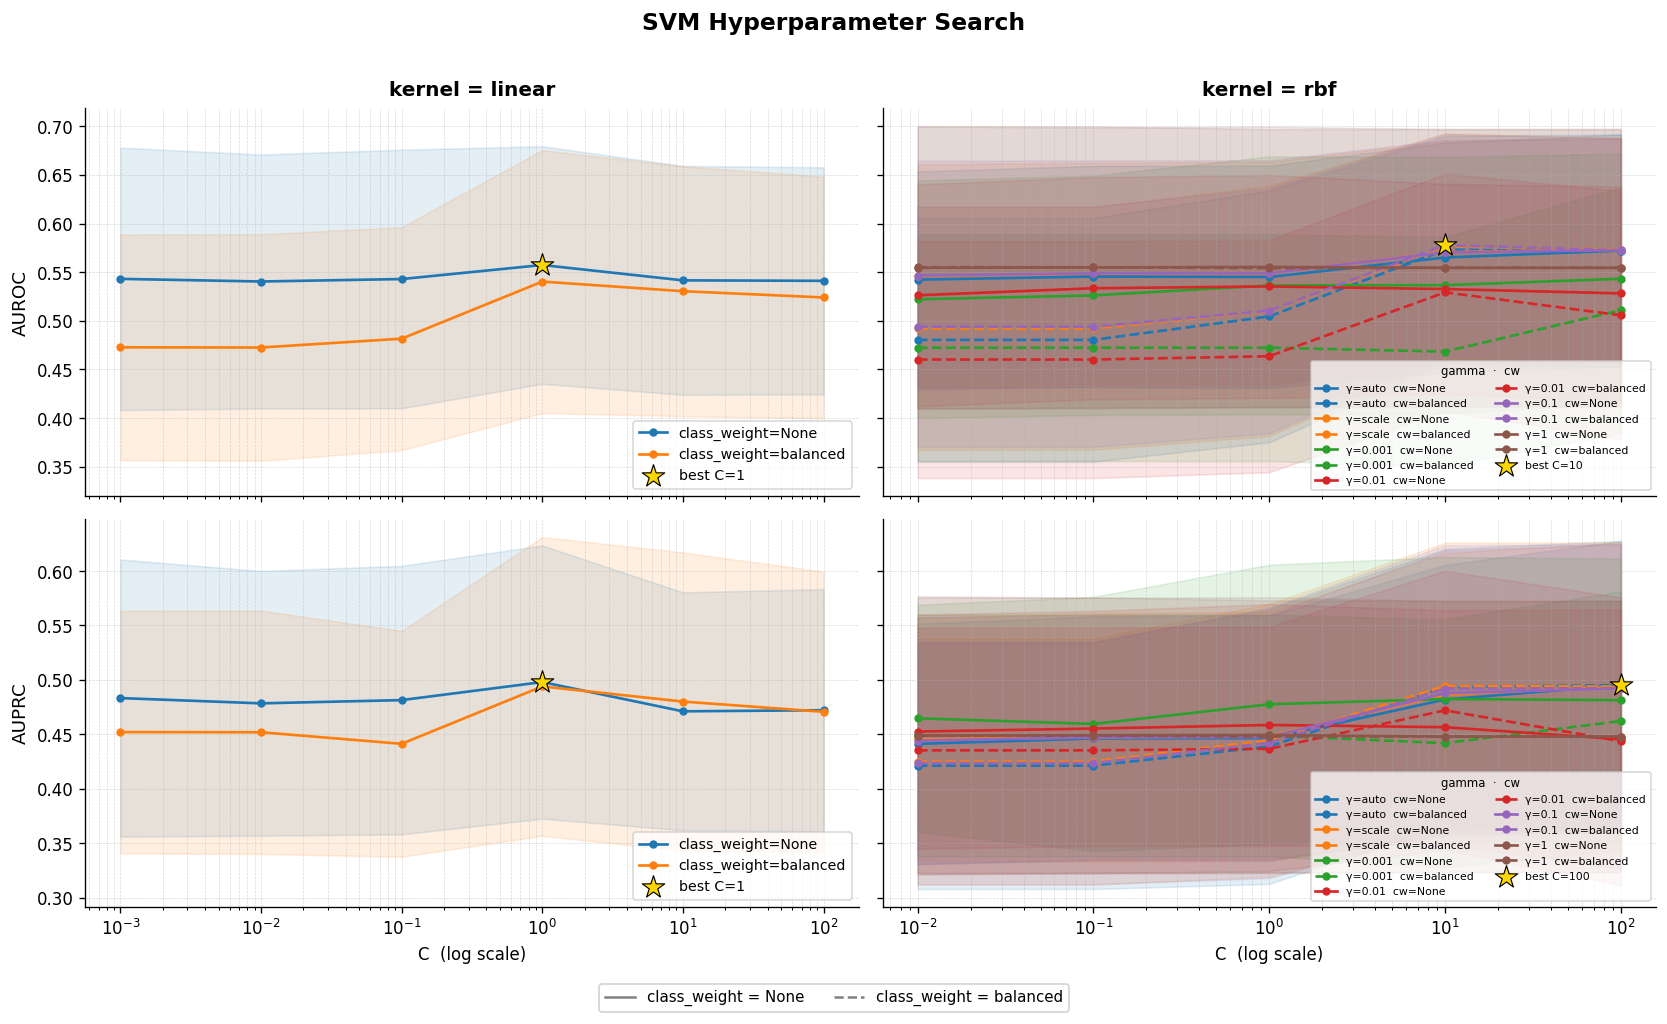

In [25]:
plot_svm_hyperparam_search(param_res)


In [26]:
best_svm_model = grid.best_estimator_

## Part D. Model Training and Cross-Validation
##### Given the relatively small and imbalanced dataset, repeated stratified cross-validation was used to obtain a reliable estimate of model performance. This approach ensures that each sample contributes to both training and evaluation while preserving the class distribution across folds.

In [27]:

cv = RepeatedStratifiedKFold(n_splits=5 , n_repeats=10 , random_state=42)


result = []
all_coefficients = []
fold_prob = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]


    best_svm_model.fit(X_train, y_train)

    y_decision_score = best_svm_model.decision_function(X_test)
    y_pred = best_svm_model.predict(X_test)

    coefficients = best_svm_model.named_steps["model"].coef_[0]


    feature_names = (
        best_svm_model.named_steps["preprocessor"]
        .get_feature_names_out()
    )


    auroc = roc_auc_score(y_test, y_decision_score)

    sensitivity = recall_score(y_test, y_pred)

    avg_precision = average_precision_score(y_test, y_decision_score)

    f1score = f1_score(y_test, y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)

    result.append({"fold": fold, "AUROC":auroc, "AUPRC": 
                   avg_precision,"Sensitivity": sensitivity,
                     "Specificity": specificity , "F1_score":f1score})
    

    fold_prob.append({"fold_num": fold,
                      "indices": test_idx,
                      "y_true": y_test, 
                      "y_prob": y_decision_score, 
                      "predicted_label": y_pred})

    fold_df = pd.DataFrame({
        "Fold": fold,
        "Feature": feature_names,
        "Coefficient": coefficients
    })
    all_coefficients.append(fold_df)


    coef_df = pd.concat(all_coefficients, ignore_index=True)

fold_pred = pd.DataFrame(fold_prob)

result_df = pd.DataFrame(result)
result_df.describe()

,fold,AUROC,AUPRC,Sensitivity,Specificity,F1_score
count,50.00000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,25.50000,0.557347,0.498047,0.220000,0.839780,0.269087
std,14.57738,0.123354,0.126707,0.155986,0.130796,0.177562
min,1.00000,0.340659,0.300756,0.000000,0.461538,0.000000
25%,13.25000,0.463501,0.391121,0.142857,0.769231,0.181818
50%,25.50000,0.538462,0.474903,0.285714,0.857143,0.276190
75%,37.75000,0.620683,0.577562,0.285714,0.928571,0.390909
max,50.00000,0.836735,0.789881,0.571429,1.000000,0.600000


In [28]:
summary = result_df[["AUROC", "AUPRC", "Sensitivity", "Specificity", "F1_score"]].agg(
    ["mean", "std"]
)

In [29]:
# Saving fold results

fold_pred.to_csv(
    "results/model_eval/svm_cross_val_predictions.csv",
    index=False,
)


result_df.to_csv(
    "results/model_eval/svm_cross_val_metrics.csv",
    index=False,
)

coef_df.to_csv(
    "results/model_eval/svm_cross_val_coef.csv",
    index=False,
)

In [30]:
mean_coef_df = (
    coef_df
    .groupby("Feature")["Coefficient"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

### D2. Cross-Validation Feature Importance

##### The following plot presents the mean coefficient score with standard deviation obtained from cross validation analysis. Features with positive scores favors the responder whereas the features with negative coefficients favors non-responders. Features are ranked by the obtained coefficients.  BAP1, PBRM1, SETD2, Myeloid Inflammation and T_effector shows the strongest positive associations with Responders whereas Cell_Cycle, Angiogenesis and FAO/AMPK shows negative association with Non-Responders.


(<Figure size 1080x655.2 with 1 Axes>,
 <Axes: title={'center': 'Linear SVM Feature Importance'}, xlabel='Coefficient (positive values favor responders)'>)

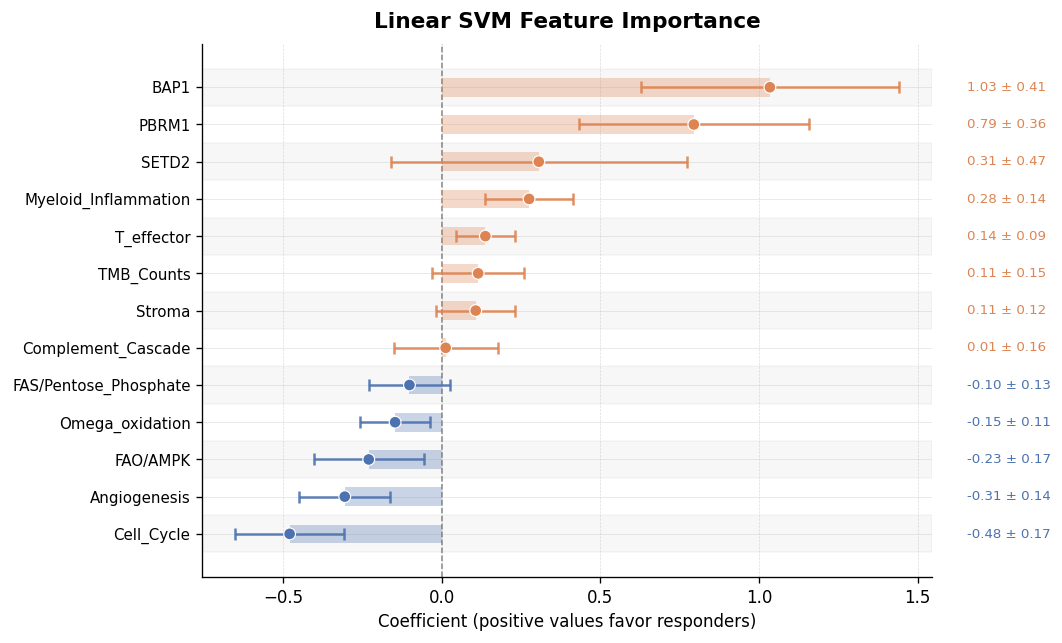

In [31]:
forest_plot_coefficients(mean_coef_df["Feature"], mean_coef_df["Coefficient"], cv_df = coef_df,col_fold = "Fold",
                         col_feature = "Feature" , col_coef = "Coefficient", title = "Linear SVM Feature Importance", 
                         mode = "coefficient" , xlabel = "Coefficient (positive values favor responders)")

### D3. Cross Validation Performance

##### The following figure summarizes the perfomance of linear SVM during repated 5-fold cross validation repeated 10 times. Each point represents one validation metrics (50 folds in total). Each boxplot represents the distribution of of the evalutation metrics across all folds. The model achived a mean AUROC of 0.56, slighlty above random performance. However the AUPRC is 0.50 which exceeds the expected baseline based on the responder prevalence (35/103 ≈ 0.34).The model demonstrated higher specificity (0.83) than sensitivity (0.22), indicating that it identified non-responders more consistently than responders. The relatively high variability in sensitivity reflects the small sample size: each training fold contained only 30 responders and 54 non-responders, while each validation fold contained approximately 5 responders and 14 non-responders. Consequently, the performance varied across different data splits, with some folds achieving sensitivity as high as 0.58 and others failing to identify any responders.

In [32]:
print(summary)

         AUROC     AUPRC  Sensitivity  Specificity  F1_score
mean  0.557347  0.498047     0.220000     0.839780  0.269087
std   0.123354  0.126707     0.155986     0.130796  0.177562


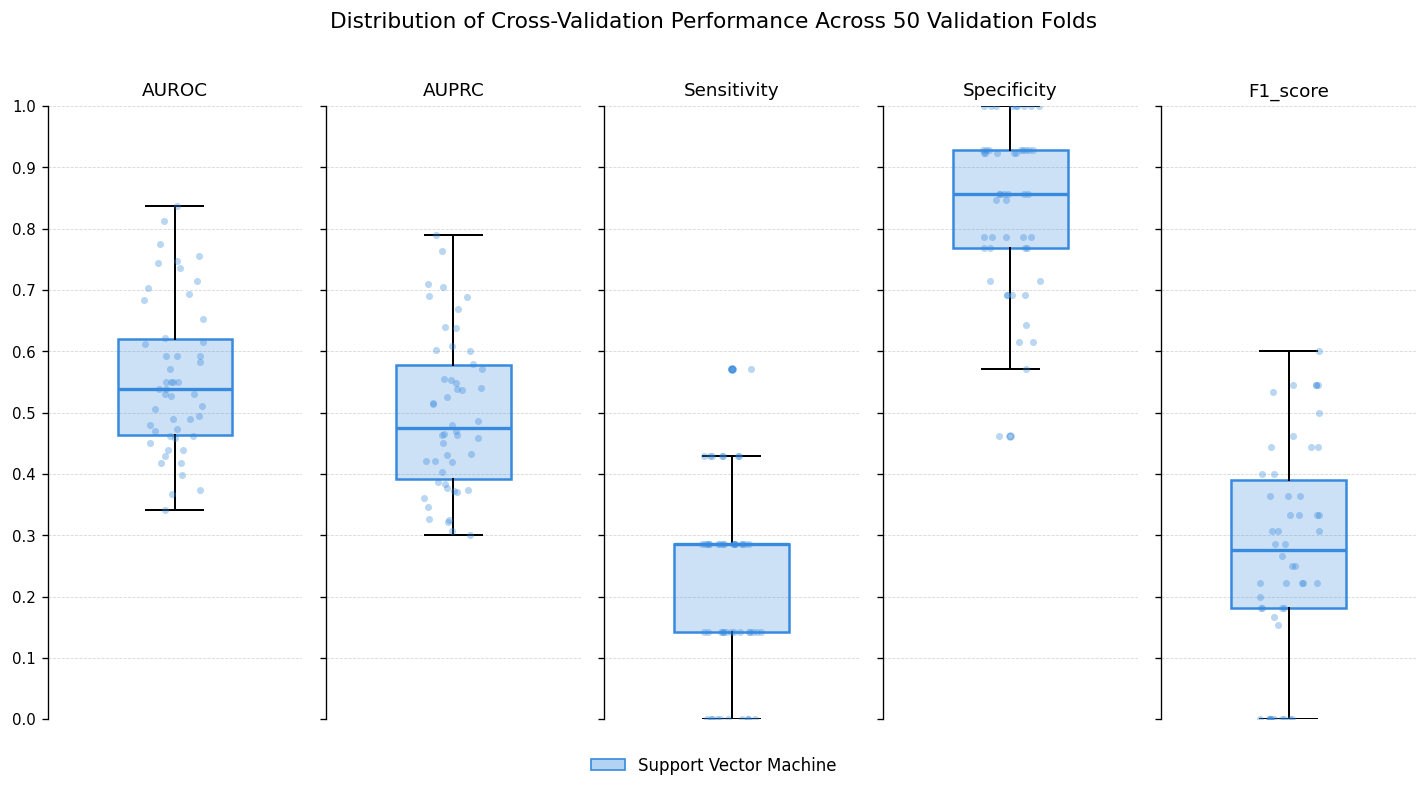

In [33]:
fig = plot_cv_metrics([result_df], ["Support Vector Machine"] , ["AUROC", "AUPRC", "Sensitivity", "Specificity", "F1_score"],  title = "Distribution of Cross-Validation Performance Across 50 Validation Folds")

### D4. Optimal Decision-Score Threshold Selection

##### Motivation: Because the training dataset is relatively small and class-imbalanced, the default decision threshold may not provide the best balance between correctly identifying responders and non-responders. An optimal threshold was therefore determined from the cross-validation predictions using Youden's Index, providing a more balanced classification rule for subsequent external validation.

##### The following figure showcase the selection of the optimal decision-score threshold from repeated 5-fold cross validation. The Left panel shows the ROC curve generated from the patient averaged out-of-fold(OOF) decision scores obtained from cross validation. The right panel shows the Youden's s (TPR-FPR) at different decision-score thresholds. The threshold corresponding to the maximum Youden's J statistic (−0.276) was selected as the optimal decision threshold and subsequently applied to the external validation cohort.

Patients: 103  |  Folds: 50  |  Avg repeats per patient: 10
Frozen threshold (youden): -0.2755  |  AUC: 0.5429


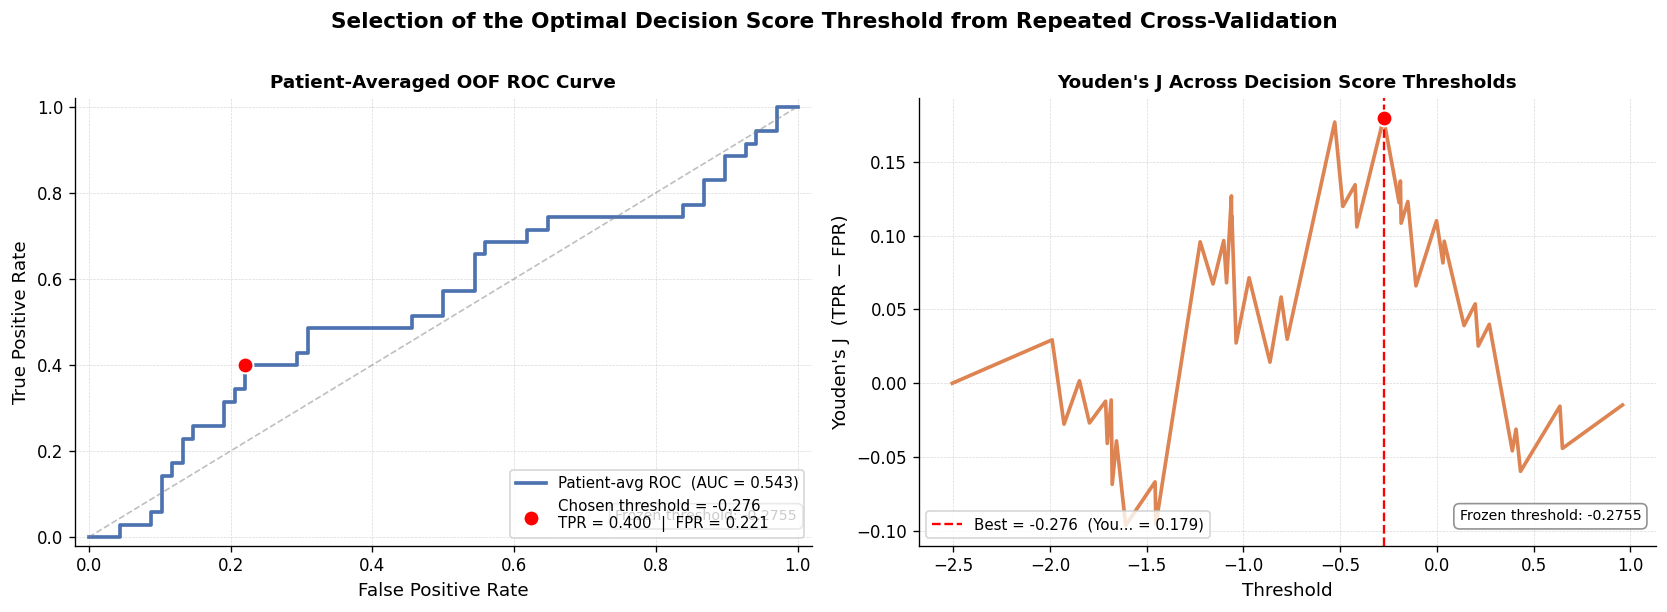

In [34]:
threshold_sel = select_threshold_from_cv(fold_prob, title="Selection of the Optimal Decision Score Threshold from Repeated Cross-Validation",
                                title_left="Patient-Averaged OOF ROC Curve", title_right="Youden's J Across Decision Score Thresholds")

### D5. Training linear svm on entire training dataset before testing on validation cohort.

In [35]:
best_svm_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binary', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers

## Part E. Performance Evaluation on the External Validation Cohort

### E1. Validation Cohort Overview

#### Gene signatures in validation cohort are derived from Microarray data of gene expression whereas the gene signatures of training cohort derived from RNA-Seq. We first converted the gene expression into z-scores individually and then computed the gene signatures to make the feature platform independent. 

In [36]:
feature_cols = X.columns.tolist()
validation_features = validation_cohort[feature_cols]

validation_features.head()

,TMB_Counts,BAP1,PBRM1,SETD2,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation
0,56.0,WT,MUT,WT,-1.249629,-1.213285,0.601988,0.093063,1.079233,-0.277245,0.162433,0.091752,0.017431
1,72.0,WT,WT,WT,-0.575128,1.039385,0.443900,-0.820964,-0.471185,0.603002,-0.547749,-0.615865,-0.642438
2,21.0,WT,WT,WT,0.294987,-0.325934,-0.015568,-1.462302,0.096124,0.470951,-0.696113,0.040591,-0.028226
3,34.0,WT,WT,WT,0.196749,-0.213276,1.201464,-0.605462,0.060638,-1.477577,-0.007022,0.858854,0.797571
4,NaN,NaN,NaN,NaN,-0.637247,-0.074359,-0.644113,-0.106279,-0.460072,0.501169,0.737388,0.209353,0.074781


### E2. Missing Data Distribution Validation Cohort

##### The following heatmap illustrates the pattern of missing values across all features in the external validation cohort. Missing values are observed only in the mutation features (PBRM1, BAP1, and SETD2) and TMB_Counts, while all remaining molecular and clinical features are complete. Missing categorical features were imputed using the most_frequent strategy, whereas the numeric TMB_Counts feature was imputed using the median. The imputation parameters were learned from the training data and then applied to the external validation cohort, ensuring consistent preprocessing while preventing information leakage

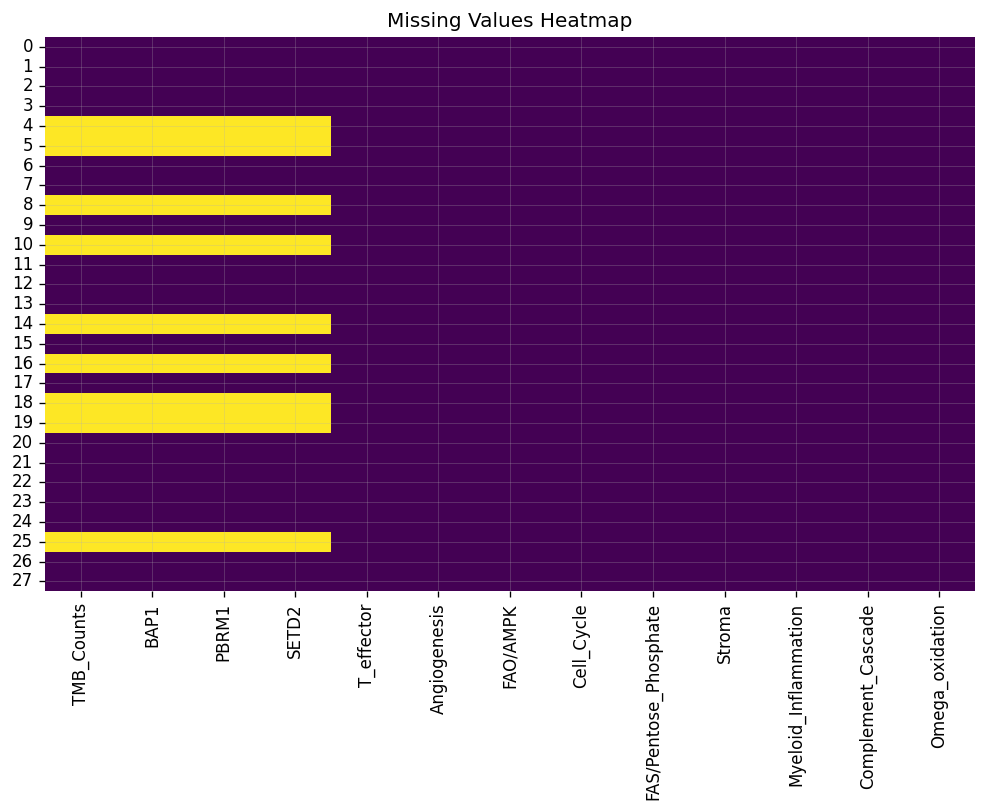

In [37]:
missin_val_heatmap(validation_features)

### E3. Binary Encoding of Categorical Features

In [38]:

validation_features.loc[~validation_features["PBRM1"].isin(["WT", np.nan]), "PBRM1"] = 1
validation_features.loc[validation_features["PBRM1"].isin(["WT"]), "PBRM1"] = 0

validation_features.loc[~validation_features["SETD2"].isin(["WT", np.nan]), "SETD2"] = 1
validation_features.loc[validation_features["SETD2"].isin(["WT"]), "SETD2"] = 0

validation_features.loc[~validation_features["BAP1"].isin(["WT", np.nan]), "BAP1"] = 1
validation_features.loc[validation_features["BAP1"].isin(["WT"]), "BAP1"] = 0

validation_features.head(5)

,TMB_Counts,BAP1,PBRM1,SETD2,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation
0,56.0,0,1,0,-1.249629,-1.213285,0.601988,0.093063,1.079233,-0.277245,0.162433,0.091752,0.017431
1,72.0,0,0,0,-0.575128,1.039385,0.443900,-0.820964,-0.471185,0.603002,-0.547749,-0.615865,-0.642438
2,21.0,0,0,0,0.294987,-0.325934,-0.015568,-1.462302,0.096124,0.470951,-0.696113,0.040591,-0.028226
3,34.0,0,0,0,0.196749,-0.213276,1.201464,-0.605462,0.060638,-1.477577,-0.007022,0.858854,0.797571
4,NaN,NaN,NaN,NaN,-0.637247,-0.074359,-0.644113,-0.106279,-0.460072,0.501169,0.737388,0.209353,0.074781


### E4. Separating dependent and target variables

In [39]:

X_val = validation_features
y_val = validation_cohort["Response"]

# Encoding target variable into binary variable.
y_val = y_val.replace({
    "Non-Responders": 0,
    "Responders": 1
})

##### External validation cohort contains 9 Responders and 19 Non-responders.

In [40]:
y_val.value_counts()

Response
0    19
1     9
Name: count, dtype: int64

## Part F. Performance on external validation cohort


### F1. Employing our final linear SVM model on external dataset. We are using decision scores for AUROC and AUPRC and obtained optimal threshold for computing specificity and sensitivity. 

In [41]:

y_decision = best_svm_model.decision_function(X_val)

y_val_pred = (y_decision >=threshold_sel["threshold"]).astype(int)

#coefficients = best_svm_model.named_steps["model"].coef_[0]

feature_names = best_svm_model.named_steps["preprocessor"].get_feature_names_out()

auroc = roc_auc_score(y_val,y_decision )

sensitivity = recall_score(y_val, y_val_pred)

avg_precision =  average_precision_score(y_val,y_decision )

f1score = f1_score(y_val, y_val_pred)

tn, fp, fn, tp = confusion_matrix(y_val, y_val_pred).ravel()
specificity = tn / (tn + fp)

print("Auroc:", auroc)
print("Auprc:", avg_precision)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)
print("F1 Score:", f1score)



Auroc: 0.695906432748538
Auprc: 0.5772486772486773
Sensitivity: 0.4444444444444444
Specificity: 0.8947368421052632
F1 Score: 0.5333333333333333


In [42]:
prediction_results = pd.DataFrame({
    "patient_id": X_val.index,
    "true_label": y_val.to_numpy(),
    "predicted_score": y_decision,
    "predicted_label_optimized": y_val_pred,
})

prediction_results.to_csv(
    "results/model_eval/svm_external_predictions.csv",
    index=False,
)


metrics = pd.DataFrame({
    "model": ["Linear SVM"],
    "dataset": ["External validation"],
    "AUROC": [auroc],
    "AUPRC": [avg_precision],
    "sensitivity": [sensitivity],
    "specificity": [specificity],
    "F1": [f1score],
    "threshold": [threshold_sel["threshold"]],
})

metrics.to_csv(
    "results/model_eval/svm_external_metrics.csv",
    index=False,
)

### F2. ROC and PR Curve 

##### The following figure presents the Receiver Operating Characteristic (ROC) and Precision–Recall (PR) curves for the linear SVM model on the external validation cohort. The model achieved an AUROC of 0.69, indicating good discrimination between responders and non-responders. The AUPRC of 0.58 exceeds the no-skill baseline (prevalence = 0.34), demonstrating improved precision in identifying responders despite the imbalanced class distribution. Using the optimal decision threshold selected during cross-validation, the model achieved a sensitivity of 0.444, correctly identifying 4 of 9 responders, and a specificity of 0.894, correctly classifying approximately 17 of 19 non-responders. The F1 score of 0.53 indicates a balanced trade-off between precision and recall. Overall, these results suggest that the model generalizes reasonably well to the independent external validation cohort.

(<Figure size 1560x720 with 2 Axes>,
 (<Axes: title={'center': 'ROC Curve'}, xlabel='False Positive Rate  (1 − Specificity)', ylabel='True Positive Rate  (Sensitivity)'>,
  <Axes: title={'center': 'Precision-Recall Curve'}, xlabel='Recall  (Sensitivity)', ylabel='Precision  (PPV)'>))

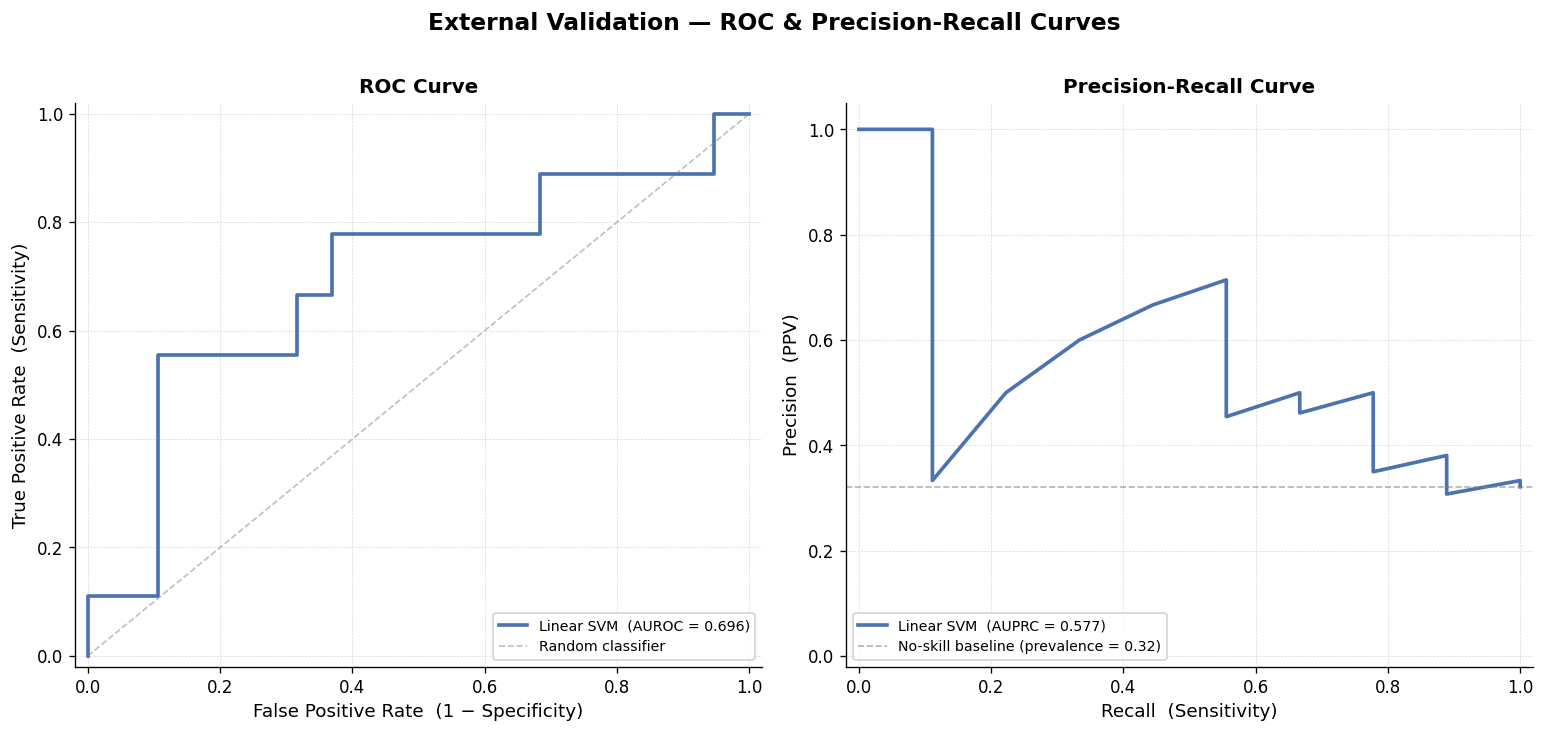

In [43]:
plot_external_validation_curves( y_true = y_val, y_prob = y_decision, model_name = "Linear SVM" )

### F3. External Validation Confusion Matrix

##### The confusion matrix shows that the model correctly identified 4 of 9 responders and 17 of 19 non-responders, while misclassifying 5 responders and 2 non-responders. These results are consistent with the observed sensitivity (44.4%) and specificity (89.4%), indicating a balanced performance across both classes.

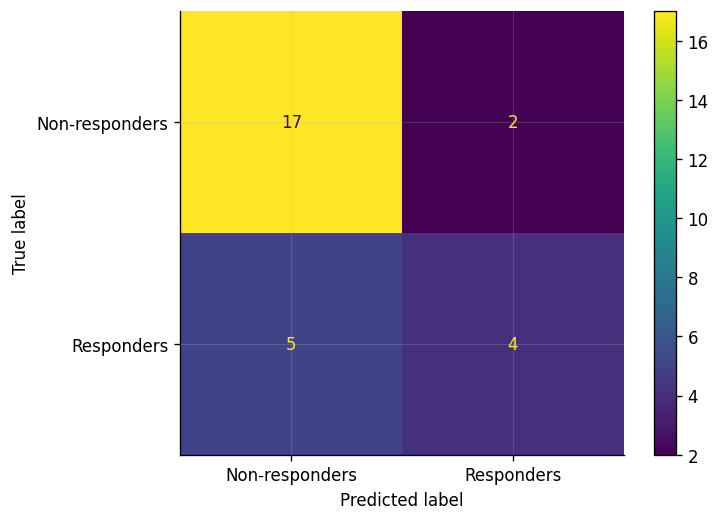

In [44]:
cm = confusion_matrix(y_val, y_val_pred)
class_names = ["Non-responders", "Responders"] 
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot()

### F4. Decision Score Distribution by True Class

##### The following violin plot shows the distribution of the linear SVM decision scores for responders and non-responders in the external validation cohort. Responders generally have higher (less negative) decision scores than non-responders, indicating that the model is able to separate the two classes. Although some overlap remains, the overall shift in score distributions is consistent with the model's moderate discriminative performance.

(<Figure size 840x600 with 1 Axes>,
 <Axes: title={'center': 'Predicted Scores by True Class'}, ylabel='Predicted Decision Score'>)

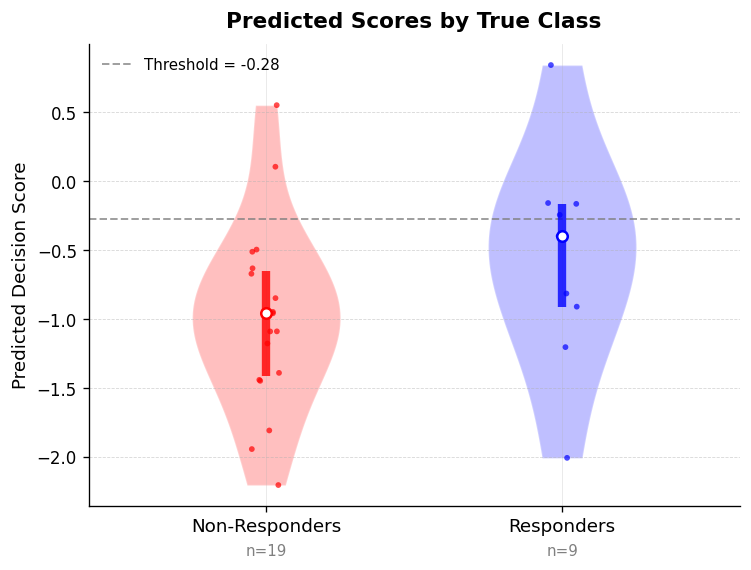

In [45]:
violin_plot_predictions(y_val,y_decision, [ "Non-Responders", "Responders"], colors = ["red", "blue"],ylabel = "Predicted Decision Score", point_alpha= 0.7, threshold=threshold_sel["threshold"])

### F4. Linear SVM Feature Importance

##### The following figure ranks the linear SVM feature coefficients according to their contribution to the classification decision on the external validation dataset. Positive coefficients increase the decision score toward the responder class, whereas negative coefficients shift predictions toward the non-responder class. PBRM1, SETD2 and BAP1,remain the strongest positive predictors of response, consistent with the feature importance observed during cross-validation. Notably, the T_effector signature also exhibits a positive coefficient, supporting its established role in reflecting a pre-existing anti-tumor immune response associated with improved immunotherapy outcomes. Conversely, Cell Cycle, Omega Oxidation and Angiogenesis contribute most strongly toward predicting non-response. Overall, the direction and relative ranking of the feature coefficients are largely consistent with those observed during cross-validation, demonstrating stable feature contributions across independent datasets.

(<Figure size 1080x655.2 with 1 Axes>,
 <Axes: title={'center': 'Linear SVM Feature Importance'}, xlabel='Coefficient (positive values favor responders)'>)

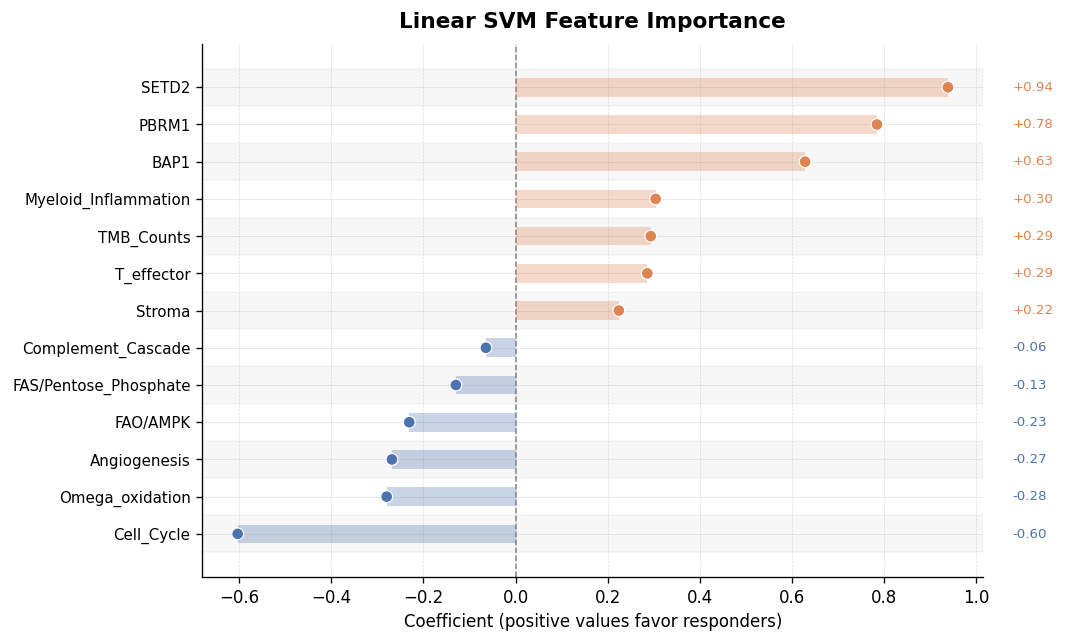

In [46]:
forest_plot_coefficients(feature_names,coefficients, title = "Linear SVM Feature Importance", 
                         mode = "coefficient" , xlabel = "Coefficient (positive values favor responders)")

## Part G. Bootstrap Analysis

##### Because the external validation cohort is relatively small, point estimates alone may not fully reflect the reliability of the model's performance. Bootstrap resampling was therefore used to estimate 95% confidence intervals for each evaluation metric, providing a more robust assessment of performance variability and uncertainty.

In [47]:
observed_metrics = calculate_binary_metrics(
    y_val,
    y_decision,
    threshold=threshold_sel["threshold"]
)


In [48]:
bootstrap_df, ci_df, skipped = bootstrap_external_metrics(
    y_true=y_val,
    y_prob=y_decision,
    threshold=threshold_sel["threshold"],
    n_bootstraps=5000,
    confidence_level=0.95,
    random_state=42
)

print(ci_df)
print("Skipped bootstrap samples:", skipped)

        metric  bootstrap_mean  bootstrap_median  ci_lower  ci_upper  \
0        AUROC        0.694089          0.700535  0.433333  0.909091   
1        AUPRC        0.602890          0.610601  0.285058  0.878723   
2  Sensitivity        0.445153          0.444444  0.125000  0.800000   
3  Specificity        0.893302          0.900000  0.733333  1.000000   
4           F1        0.515609          0.533333  0.166667  0.800000   

   valid_bootstraps  
0              5000  
1              5000  
2              5000  
3              5000  
4              5000  
Skipped bootstrap samples: 0


In [49]:
report_df = pd.DataFrame({
    "metric": observed_metrics.keys(),
    "estimate": observed_metrics.values()
})

report_df = report_df.merge(
    ci_df[
        [
            "metric",
            "ci_lower",
            "ci_upper",
            "valid_bootstraps"
        ]
    ],
    on="metric",
    how="left"
)

print(report_df)

        metric  estimate  ci_lower  ci_upper  valid_bootstraps
0        AUROC  0.695906  0.433333  0.909091              5000
1        AUPRC  0.577249  0.285058  0.878723              5000
2  Sensitivity  0.444444  0.125000  0.800000              5000
3  Specificity  0.894737  0.733333  1.000000              5000
4           F1  0.533333  0.166667  0.800000              5000


### Bootstrap 95% Confidence Intervals

##### The following figure summarizes the bootstrap 95% confidence intervals for the external validation performance metrics. The point estimates correspond to the observed performance, and the error bars represent the uncertainty estimated from 1,000 bootstrap resamples. While AUROC demonstrates good discriminative performance, the wider confidence intervals for the remaining metrics reflect the relatively small external validation cohort. Overall, the bootstrap analysis indicates that the model's performance is reasonably stable while highlighting the uncertainty associated with evaluation on a limited sample size.

(<Figure size 1080x600 with 1 Axes>,
 <Axes: title={'center': 'Bootstrap 95% CI — Model Performance'}, xlabel='Metric value'>)

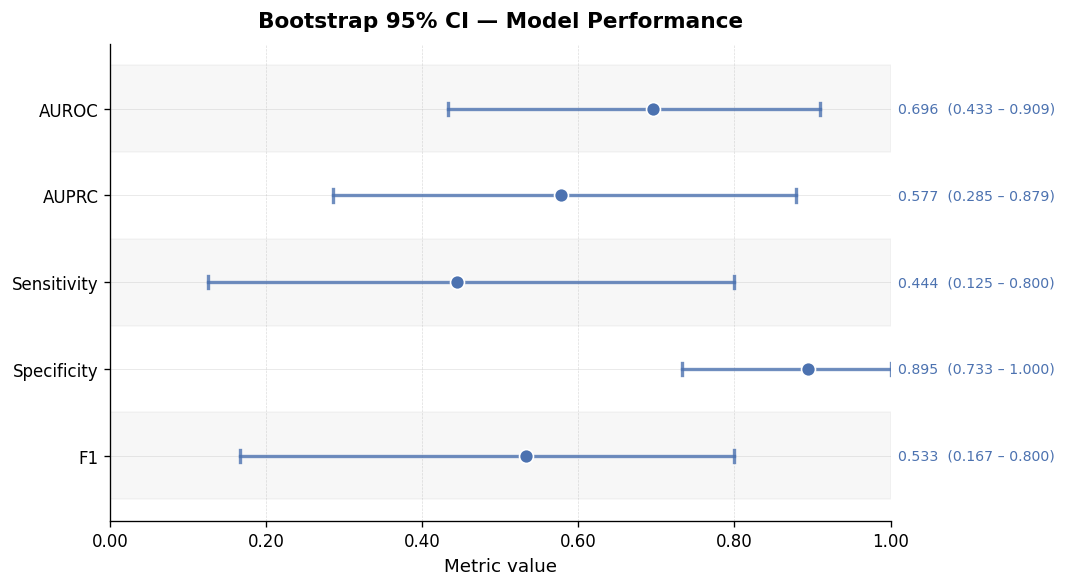

In [50]:
plot_bootstrap_ci_forest(report_df)

# Conclusion

##### 
##### 1. The linear SVM model was developed using repeated stratified cross-validation, hyperparameter tuning, and decision threshold optimization to predict immunotherapy response in patients with clear cell renal cell carcinoma. 
##### 2. While cross-validation performance was modest (AUROC = 0.56), the model demonstrated improved discrimination on the independent external validation cohort (AUROC = 0.69), suggesting that it was able to capture predictive patterns that generalized beyond the training data.
##### 3. Feature coefficient analysis consistently identified BAP1, PBRM1, SETD2, and the T_effector signature as important positive contributors to treatment response, with similar coefficient trends observed in both cross-validation and external validation. 
##### 4. However, the relatively small and class-imbalanced training cohort limits the stability of the learned decision boundary, and the wide bootstrap confidence intervals indicate considerable uncertainty in the estimated performance metrics. 
##### 4. Consequently, these findings should be interpreted as preliminary and would benefit from validation in larger, independent cohorts. Overall, this analysis demonstrates a complete and reproducible machine learning workflow from data preprocessing and model development to external validation and model interpretation for predicting immunotherapy response using molecular and clinical features.